<a href="https://colab.research.google.com/github/VasilisPapageorgiou/Reliability---Partially-Observed/blob/main/Sim3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Η έξοδος ροής περικόπηκε στις τελευταίες 5000 γραμμές.
Fitting sample|hyper_fast|200|0
Completed sample|hyper_fast|200|0
Fitting sample|erlang_fast|200|0
Completed sample|erlang_fast|200|0
Fitting sample|erlang_variable_repair|200|0
Completed sample|erlang_variable_repair|200|0
Fitting sample|exponential|200|0
Completed sample|exponential|200|0
Fitting sample|hyper_fast|800|0
Completed sample|hyper_fast|800|0
Fitting sample|erlang_fast|800|0
Completed sample|erlang_fast|800|0
Fitting sample|erlang_variable_repair|800|0
Completed sample|erlang_variable_repair|800|0
Fitting sample|exponential|800|0
Completed sample|exponential|800|0
Fitting sample|hyper_fast|3200|0
Completed sample|hyper_fast|3200|0
Fitting sample|erlang_fast|3200|0
Completed sample|erlang_fast|3200|0
Fitting sample|erlang_variable_repair|3200|0
Completed sample|erlang_variable_repair|3200|0
Fitting sample|exponential|3200|0
Completed sample|exponential|3200|0
Checkpoint saved 19 completed tasks
Fitting sample|hyper_fast

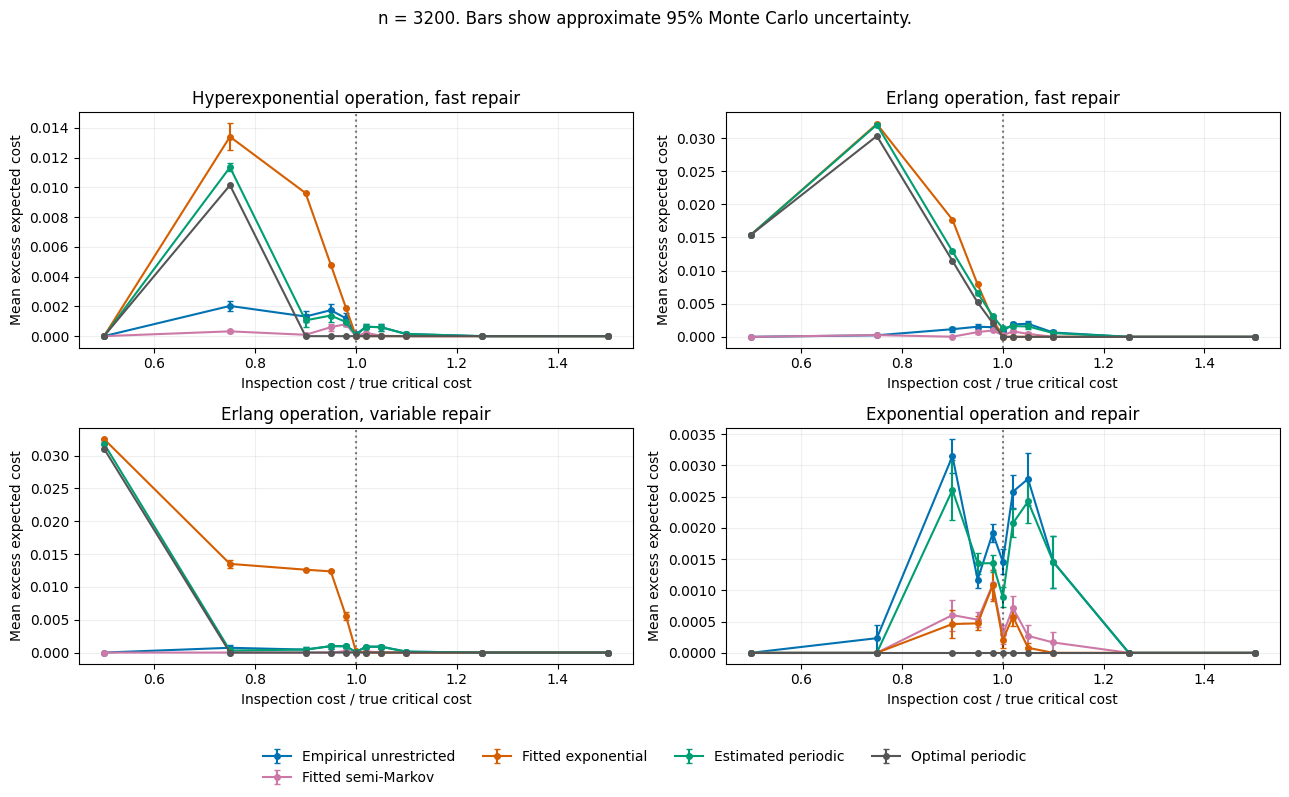

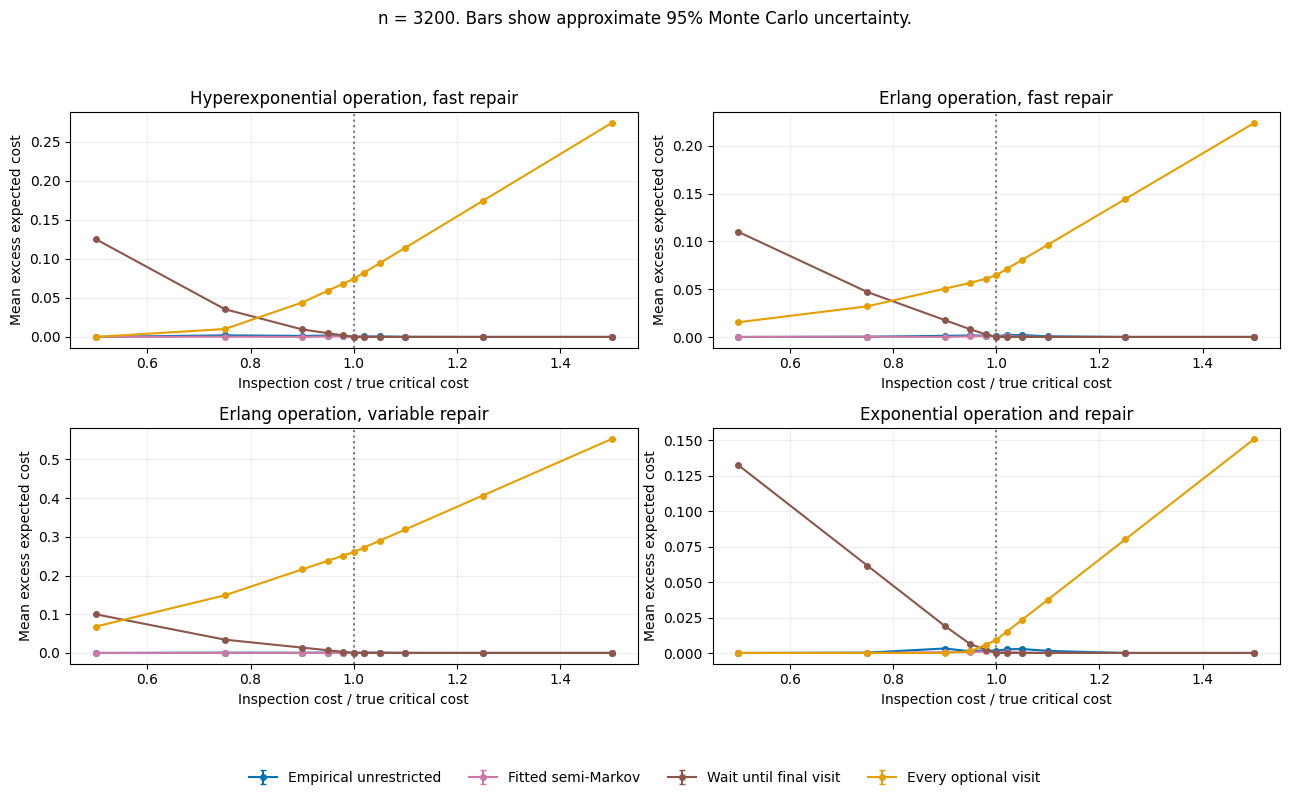

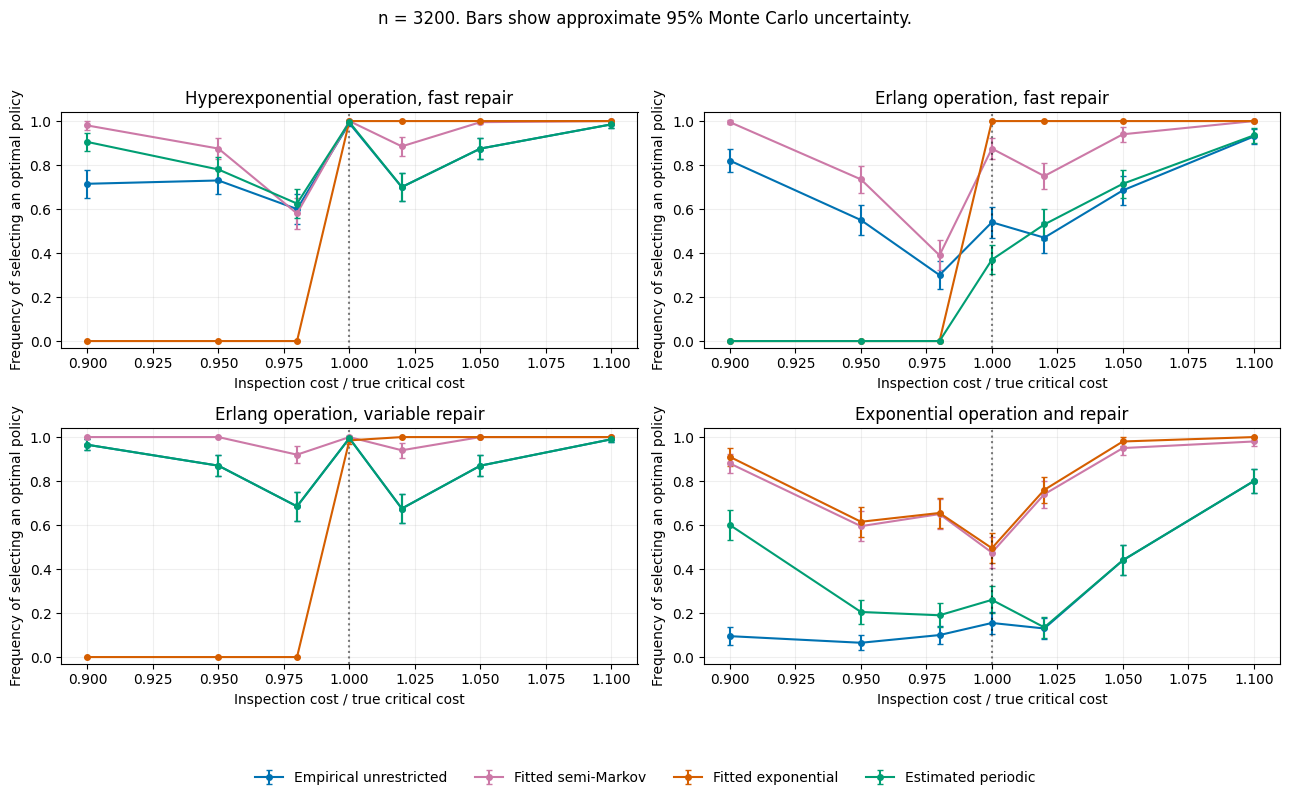

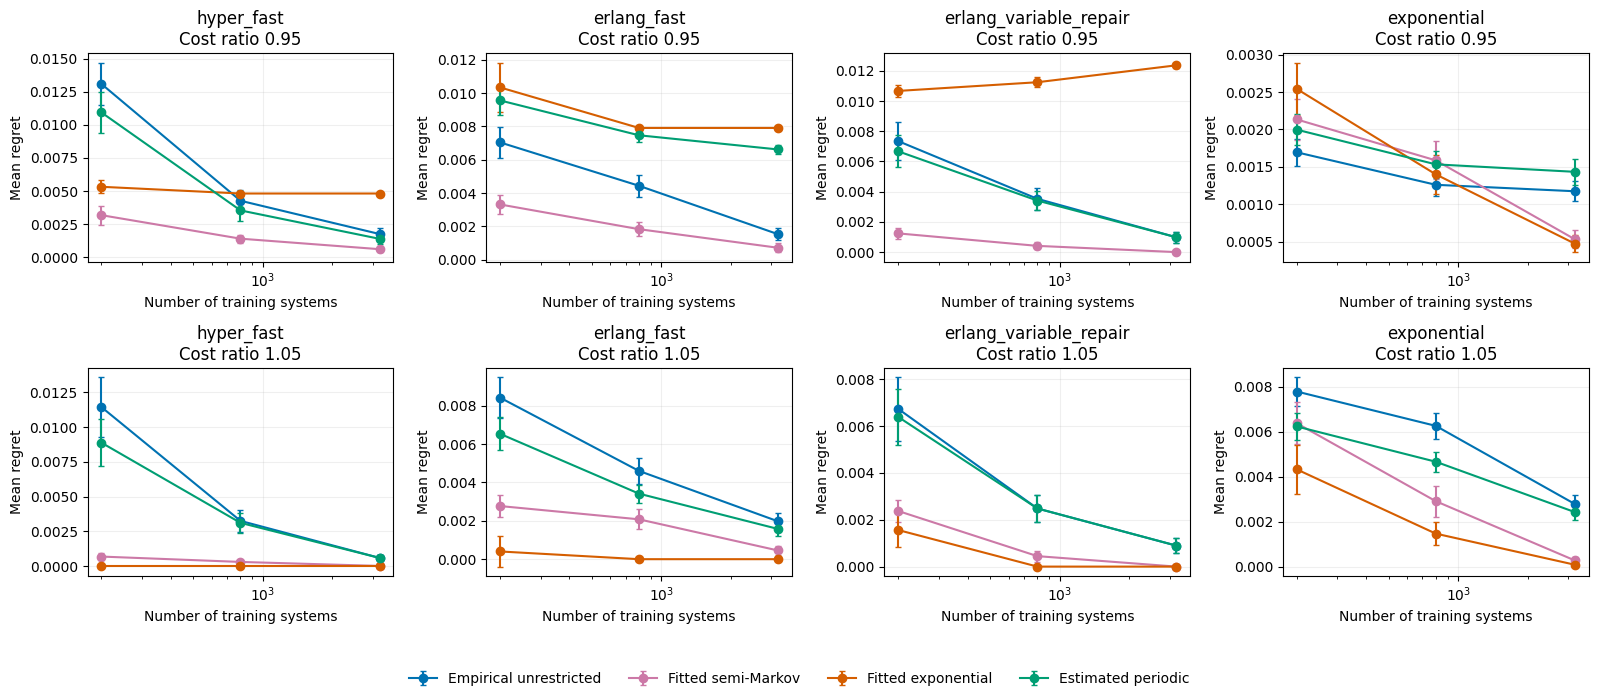

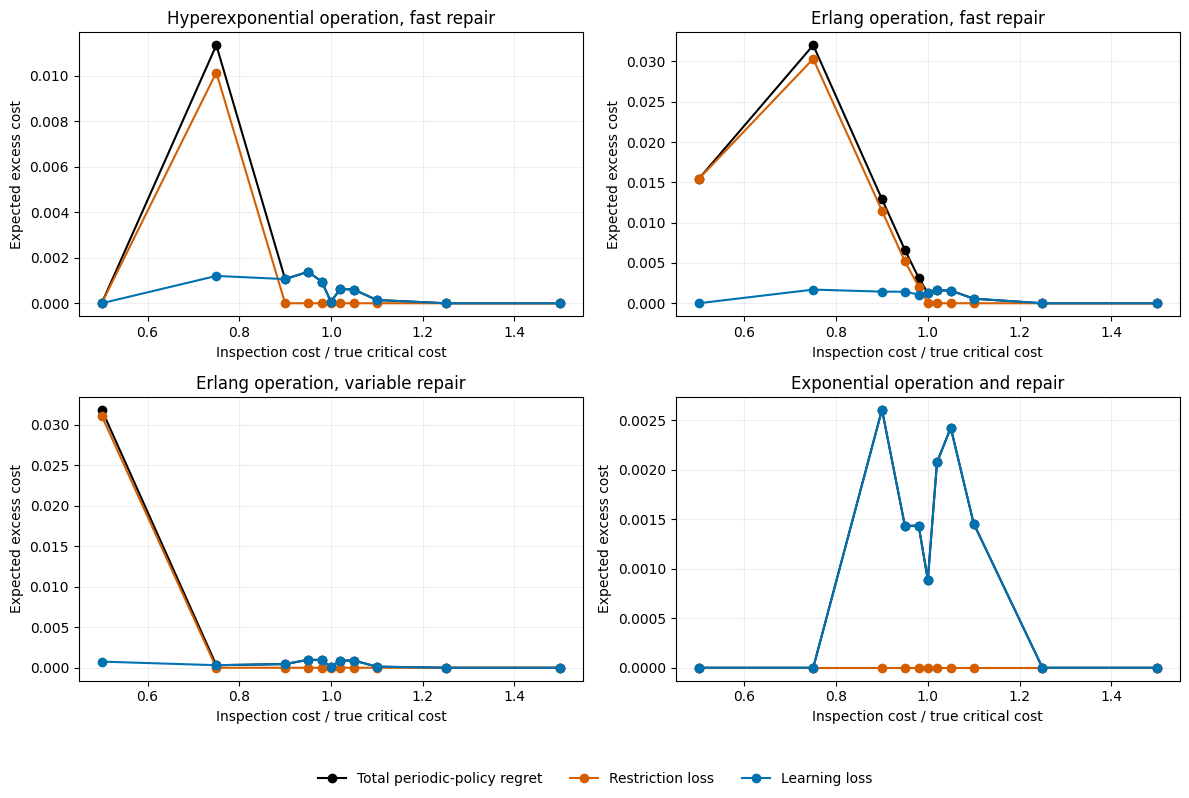

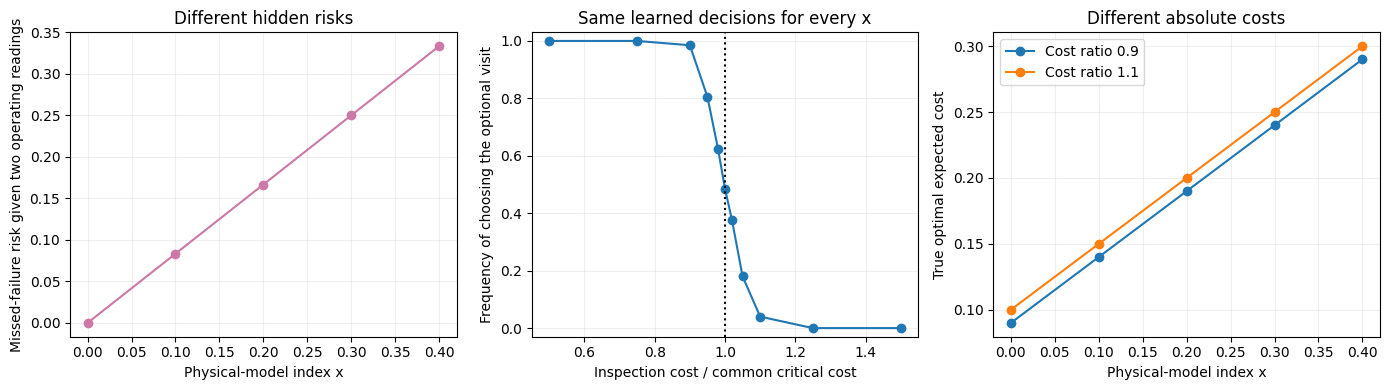

Checkpoint saved 2606 completed tasks
Completed. Results are in /content/SemiMarkov_Experiments/experiment_3_strengthened
Inspect population_fits.csv and optimizer_review.csv first.
Then inspect paired_comparisons.csv and optimal_selection_counts.csv.
Download progress before the Colab runtime is deleted.
Checkpoint saved 2606 completed tasks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ================================================================
# STRENGTHENED EXPERIMENT 3
# Learning optimal inspection policies under partial observation
#
# Main analyses
#   1. Policy regret and optimal-policy selection
#   2. Policy restriction loss versus estimation loss
#   3. Critical-cost estimation
#   4. Population model-misspecification diagnostics
#   5. Identical decisions with different hidden risks
#
# Training data contain all binary readings on the candidate grid.
# Execution policies observe only the visits they select.
# Inspections do not alter the physical process.
# Optional inspections stop after a failure is detected.
# The final inspection is always required.
# The missed-failure penalty is normalized to one.
#
# No Google Drive connection.
# Checkpoints retain completed tasks.
# ================================================================

import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import json
import gzip
import time
import hashlib
import itertools
import shutil
import platform
import uuid
import zipfile
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy.linalg import expm, expm_frechet, block_diag
from scipy.optimize import minimize


# ================================================================
# Configuration
# ================================================================

PROFILE = "publication"       # "diagnostic" or "publication"
SEED = 20261117
CHECKPOINT_SECONDS = 20 * 60
RUN_VALIDATION = True
DOWNLOAD_ON_FINISH = True

CODE_VERSION = "experiment3_strengthened_v1"

PROFILES = {
    "diagnostic": {
        "repetitions": 3,
        "sample_sizes": [200, 800],
        "starts": 6,
        "grid_side": 5,
        "maxiter": 250,
        "validation_systems": 10000,
    },
    "publication": {
        "repetitions": 200,
        "sample_sizes": [200, 800, 3200],
        "starts": 10,
        "grid_side": 5,
        "maxiter": 400,
        "validation_systems": 30000,
    },
}

if PROFILE not in PROFILES:
    raise ValueError("Choose diagnostic or publication.")

CFG = PROFILES[PROFILE].copy()

H = 6.0
TIMES = np.linspace(0.0, H, 7)
DT = float(TIMES[1] - TIMES[0])
NUMBER_FOLLOWUPS = len(TIMES) - 1

SHAPES = (0, 1, 3)
SHAPE_PAIRS = tuple(itertools.product(SHAPES, repeat=2))
MEAN_BOUNDS = (0.12, 30.0)
LOG_BOUNDS = np.log(np.array(MEAN_BOUNDS))

COST_RATIOS = (
    0.50, 0.75, 0.90, 0.95, 0.98,
    1.00, 1.02, 1.05, 1.10, 1.25, 1.50,
)

# Numerical tolerances, not statistical significance thresholds.
TIE_TOLERANCE = 1e-10
GRADIENT_TOLERANCE = 1e-5
BOUNDARY_TOLERANCE = 1e-5

SCENARIOS = [
    {
        "scenario": "hyper_fast",
        "label": "Hyperexponential operation, fast repair",
        "parameters": (0, 3, 4.0, 0.3),
    },
    {
        "scenario": "erlang_fast",
        "label": "Erlang operation, fast repair",
        "parameters": (3, 3, 4.0, 0.3),
    },
    {
        "scenario": "erlang_variable_repair",
        "label": "Erlang operation, variable repair",
        "parameters": (3, 0, 4.0, 1.2),
    },
    {
        "scenario": "exponential",
        "label": "Exponential operation and repair",
        "parameters": (1, 1, 4.0, 0.3),
    },
]

LEARNED_METHODS = (
    "empirical",
    "fitted_phase",
    "fitted_exponential",
    "empirical_regular",
)

METHOD_LABELS = {
    "empirical": "Empirical unrestricted",
    "fitted_phase": "Fitted semi-Markov",
    "fitted_exponential": "Fitted exponential",
    "empirical_regular": "Estimated periodic",
    "oracle_regular": "Optimal periodic",
    "oracle_unrestricted": "Optimal unrestricted",
    "wait": "Wait until final visit",
    "all_visits": "Every optional visit",
}

COLORS = {
    "empirical": "#0072B2",
    "fitted_phase": "#CC79A7",
    "fitted_exponential": "#D55E00",
    "empirical_regular": "#009E73",
    "oracle_regular": "#555555",
    "oracle_unrestricted": "#000000",
    "wait": "#8C564B",
    "all_visits": "#E69F00",
}

BASE = (
    Path("/content") if Path("/content").exists() else Path.cwd()
) / "SemiMarkov_Experiments"

ROOT = BASE / "experiment_3_strengthened"
CP = None


# ================================================================
# Checkpoints
# ================================================================

def json_default(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot serialize {type(value)}")


def reproducible_rng(key):
    digest = hashlib.sha256(f"{SEED}|{key}".encode()).digest()
    return np.random.default_rng(
        int.from_bytes(digest[:8], "little")
    )


class LocalCheckpoint:
    def __init__(self, root, metadata):
        self.root = Path(root)
        self.metadata = metadata

        self.fingerprint = hashlib.sha256(
            json.dumps(metadata, sort_keys=True).encode()
        ).hexdigest()

        choice = input("Enter 1 to START NEW or 2 to RESUME  ").strip()
        while choice not in {"1", "2"}:
            choice = input("Please enter 1 or 2  ").strip()

        self.root.parent.mkdir(parents=True, exist_ok=True)

        if choice == "1" and self.root.exists():
            destination = self.root.with_name(
                self.root.name
                + "_archive_"
                + time.strftime("%Y%m%d_%H%M%S")
                + "_"
                + uuid.uuid4().hex[:6]
            )
            shutil.move(str(self.root), str(destination))
            print("Previous run preserved in", destination)

        self.root.mkdir(parents=True, exist_ok=True)
        self.path = self.root / "checkpoint.json.gz"

        if choice == "2":
            if self.path.exists():
                raw = self.path.read_bytes()
            else:
                print("Upload a checkpoint from this code version.")
                try:
                    from google.colab import files
                except ImportError as exc:
                    raise FileNotFoundError(
                        f"Place checkpoint.json.gz in {self.root}"
                    ) from exc

                uploaded = files.upload()
                candidates = [
                    data for name, data in uploaded.items()
                    if name.endswith(".json.gz")
                ]
                if len(candidates) != 1:
                    raise ValueError("Upload exactly one .json.gz checkpoint.")
                raw = candidates[0]

            self.state = json.loads(
                gzip.decompress(raw).decode("utf-8")
            )
            if self.state.get("fingerprint") != self.fingerprint:
                raise ValueError(
                    "Checkpoint settings differ from this configuration."
                )
            if not isinstance(self.state.get("tasks"), dict):
                raise ValueError("Invalid checkpoint task table.")
        else:
            self.state = {
                "fingerprint": self.fingerprint,
                "metadata": metadata,
                "tasks": {},
            }

        self.last_save = time.monotonic()
        print("Completed tasks available", len(self.state["tasks"]))
        self.save()

    def has(self, key):
        return key in self.state["tasks"]

    def commit(self, key, tables):
        self.state["tasks"][key] = tables
        self.tick()

    def save(self):
        self.state["saved_at_utc"] = time.strftime(
            "%Y-%m-%dT%H:%M:%SZ", time.gmtime()
        )
        raw = json.dumps(
            self.state, default=json_default, allow_nan=True
        ).encode("utf-8")

        temporary = self.root / "checkpoint.tmp.gz"
        with gzip.open(temporary, "wb") as stream:
            stream.write(raw)
        os.replace(temporary, self.path)

        self.last_save = time.monotonic()
        print(
            "Checkpoint saved",
            len(self.state["tasks"]),
            "completed tasks",
            flush=True,
        )

    def tick(self):
        if time.monotonic() - self.last_save >= CHECKPOINT_SECONDS:
            self.save()

    def frame(self, name):
        rows = []
        for tables in self.state["tasks"].values():
            rows.extend(tables.get(name, []))
        return pd.DataFrame(rows)

    def export(self):
        names = {
            name
            for tables in self.state["tasks"].values()
            for name in tables
        }
        for name in sorted(names):
            self.frame(name).to_csv(
                self.root / f"{name}.csv", index=False
            )
        (self.root / "configuration.json").write_text(
            json.dumps(self.metadata, indent=2), encoding="utf-8"
        )


def heartbeat():
    if CP is not None:
        CP.tick()


def download_checkpoint():
    if CP is None:
        raise RuntimeError("Checkpoint manager is not initialized.")
    CP.save()
    try:
        from google.colab import files
        files.download(str(CP.path))
    except ImportError:
        print(CP.path)


def download_results():
    if CP is not None:
        CP.save()
        CP.export()

    archive = ROOT.parent / f"{ROOT.name}_results.zip"

    with zipfile.ZipFile(
        archive, "w", compression=zipfile.ZIP_DEFLATED
    ) as output:
        for path in sorted(ROOT.iterdir()):
            if path.is_file():
                output.write(path, arcname=path.name)

    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        print("Results archive", archive)


# ================================================================
# Physical system
# ================================================================

def duration_block(shape, mean):
    if shape == 0:
        rates = (
            np.array([0.6, 3.0])
            * (0.5 / 0.6 + 0.5 / 3.0) / mean
        )
        return np.array([0.5, 0.5]), -np.diag(rates)

    a = np.zeros(shape)
    a[0] = 1.0
    T = -np.eye(shape) * shape / mean

    if shape > 1:
        T[np.arange(shape - 1), np.arange(1, shape)] = shape / mean

    return a, T


@lru_cache(maxsize=2048)
def physical_model(k0, k1, mean0, mean1):
    a, T = duration_block(k0, mean0)
    b, U = duration_block(k1, mean1)

    Q = block_diag(T, U)
    d = len(a)
    Q[:d, d:] = np.outer(-T.sum(axis=1), b)
    Q[d:, :d] = np.outer(-U.sum(axis=1), a)

    initial = np.r_[a, np.zeros(len(b))]
    states = np.r_[np.zeros(d, dtype=int), np.ones(len(b), dtype=int)]

    dQ0 = np.zeros_like(Q)
    dQ1 = np.zeros_like(Q)
    dQ0[:d, :] = -Q[:d, :]
    dQ1[d:, :] = -Q[d:, :]

    return Q, initial, states, T, a, dQ0, dQ1


def observation_law(parameters, derivatives=False):
    heartbeat()
    Q, initial, states, _, _, dQ0, dQ1 = physical_model(
        *tuple(parameters)
    )

    P = expm(Q * DT)
    rows = initial[None, :]

    if derivatives:
        dP = np.stack([
            expm_frechet(Q * DT, dQ0 * DT, compute_expm=False),
            expm_frechet(Q * DT, dQ1 * DT, compute_expm=False),
        ])
        drows = np.zeros((2, 1, len(initial)))

    for _ in range(NUMBER_FOLLOWUPS):
        predicted = rows @ P

        if derivatives:
            dpredicted = np.stack([
                drows[j] @ P + rows @ dP[j]
                for j in range(2)
            ])

        updated = np.empty((2 * len(rows), len(initial)))
        updated[0::2] = predicted * (states == 0)
        updated[1::2] = predicted * (states == 1)

        if derivatives:
            dupdated = np.empty((2, 2 * len(rows), len(initial)))
            dupdated[:, 0::2] = dpredicted * (states == 0)
            dupdated[:, 1::2] = dpredicted * (states == 1)
            drows = dupdated

        rows = updated

    probabilities = rows.sum(axis=1)

    if probabilities.min() < -1e-9:
        raise FloatingPointError("Negative record probability.")
    if abs(probabilities.sum() - 1) > 1e-8:
        raise FloatingPointError("Record probabilities do not sum to one.")

    probabilities = np.maximum(probabilities, 0.0)

    if derivatives:
        return probabilities, drows.sum(axis=2).T

    return probabilities


def uninterrupted_probability(parameters):
    _, _, _, T, a, _, _ = physical_model(*tuple(parameters))
    return float(a @ expm(T * H) @ np.ones(len(a)))


def all_operating_risk(parameters, probabilities=None):
    if probabilities is None:
        probabilities = observation_law(parameters)

    value = 1 - uninterrupted_probability(parameters) / probabilities[0]

    if value < -1e-8 or value > 1 + 1e-8:
        raise FloatingPointError("Missed-failure risk outside [0,1].")

    return float(np.clip(value, 0, 1))


def record_kl(truth, fitted):
    value = float(
        truth @ np.log(
            np.maximum(truth, 1e-300) / np.maximum(fitted, 1e-300)
        )
    )
    if value < -1e-8:
        raise FloatingPointError("Materially negative KL divergence.")
    return max(0.0, value)


def encode(readings):
    return readings @ (
        2 ** np.arange(readings.shape[1] - 1, -1, -1)
    )


def draw_duration(shape, mean, rng):
    if shape == 0:
        rates = (
            np.array([0.6, 3.0])
            * (0.5 / 0.6 + 0.5 / 3.0) / mean
        )
        return rng.exponential(1 / rng.choice(rates))
    return rng.gamma(shape, mean / shape)


def simulate(parameters, n, rng):
    k0, k1, mean0, mean1 = parameters
    readings = np.zeros((n, NUMBER_FOLLOWUPS), dtype=int)
    failed = np.zeros(n, dtype=bool)

    for system in range(n):
        if system % 100 == 0:
            heartbeat()

        t = 0.0
        state = 0
        transitions = []

        while t < H:
            t += draw_duration(
                k0 if state == 0 else k1,
                mean0 if state == 0 else mean1,
                rng,
            )
            if t > H:
                break

            state = 1 - state
            transitions.append(t)
            if state == 1:
                failed[system] = True

        readings[system] = np.searchsorted(
            transitions, TIMES[1:], side="right"
        ) % 2

    return readings, failed


# ================================================================
# Likelihood optimization
# ================================================================

def parameters_from_logs(shape_pair, z):
    return (
        int(shape_pair[0]),
        int(shape_pair[1]),
        float(np.exp(z[0])),
        float(np.exp(z[1])),
    )


def objective(z, shape_pair, frequencies):
    probabilities, gradient = observation_law(
        parameters_from_logs(shape_pair, z),
        derivatives=True,
    )
    safe = np.maximum(probabilities, 1e-300)

    value = -float(frequencies @ np.log(safe))
    derivative = -np.sum(
        (frequencies / safe)[:, None] * gradient, axis=0
    )
    return value, derivative


def objective_value(z, shape_pair, frequencies):
    probabilities = observation_law(
        parameters_from_logs(shape_pair, z)
    )
    return -float(frequencies @ np.log(np.maximum(probabilities, 1e-300)))


def projected_gradient(z, gradient):
    result = np.asarray(gradient, dtype=float).copy()
    lower = z - LOG_BOUNDS[0] <= BOUNDARY_TOLERANCE
    upper = LOG_BOUNDS[1] - z <= BOUNDARY_TOLERANCE

    result[lower & (result > 0)] = 0
    result[upper & (result < 0)] = 0

    return float(np.max(abs(result)))


def is_boundary(z):
    return bool(np.any(
        (z - LOG_BOUNDS[0] <= BOUNDARY_TOLERANCE)
        | (LOG_BOUNDS[1] - z <= BOUNDARY_TOLERANCE)
    ))


def fit_shape(frequencies, shape_pair, key):
    axis = np.linspace(
        LOG_BOUNDS[0], LOG_BOUNDS[1], CFG["grid_side"]
    )

    coarse = []
    for z in itertools.product(axis, repeat=2):
        z = np.array(z, dtype=float)
        coarse.append({
            "z": z,
            "objective": objective_value(z, shape_pair, frequencies),
            "success": False,
            "source": "coarse",
            "iterations": 0,
        })

    starts = []
    for candidate in sorted(coarse, key=lambda item: item["objective"]):
        if all(
            np.linalg.norm(candidate["z"] - previous) > 0.5
            for previous in starts
        ):
            starts.append(candidate["z"].copy())
        if len(starts) >= CFG["starts"] // 2:
            break

    rng = reproducible_rng(f"optimization|{key}|{shape_pair}")

    while len(starts) < CFG["starts"]:
        starts.append(rng.uniform(LOG_BOUNDS[0], LOG_BOUNDS[1], size=2))

    runs = []

    def optimize(z, source, maxiter, ftol, gtol):
        result = minimize(
            objective,
            z,
            args=(shape_pair, frequencies),
            jac=True,
            method="L-BFGS-B",
            bounds=[tuple(LOG_BOUNDS)] * 2,
            options={
                "maxiter": maxiter,
                "ftol": ftol,
                "gtol": gtol,
                "maxls": 50,
            },
        )
        if not np.isfinite(result.fun):
            raise FloatingPointError("Nonfinite optimizer result.")

        return {
            "z": np.asarray(result.x, dtype=float),
            "objective": float(result.fun),
            "success": bool(result.success),
            "source": source,
            "iterations": int(result.nit),
        }

    for index, z in enumerate(starts):
        runs.append(optimize(
            z, f"start_{index}", CFG["maxiter"], 1e-12, 1e-8
        ))

    best_initial = min(
        coarse + runs, key=lambda item: item["objective"]
    )
    runs.append(optimize(
        best_initial["z"],
        "refinement",
        2 * CFG["maxiter"],
        1e-14,
        1e-10,
    ))

    best = min(coarse + runs, key=lambda item: item["objective"])
    value, gradient = objective(best["z"], shape_pair, frequencies)

    run_values = np.array([item["objective"] for item in runs])

    return {
        "parameters": parameters_from_logs(shape_pair, best["z"]),
        "objective": float(value),
        "success": best["success"],
        "source": best["source"],
        "boundary": is_boundary(best["z"]),
        "projected_gradient": projected_gradient(best["z"], gradient),
        "within_shape_spread": float(run_values.max() - run_values.min()),
        "agreement_fraction": float(np.mean(
            run_values - value <= 1e-7
        )),
        "iterations": best["iterations"],
    }


def fit_family(frequencies, key):
    fits = {
        shape_pair: fit_shape(frequencies, shape_pair, key)
        for shape_pair in SHAPE_PAIRS
    }
    best_pair = min(
        fits, key=lambda pair: fits[pair]["objective"]
    )
    return fits[best_pair], fits[(1, 1)], fits


# ================================================================
# Policy representation
# ================================================================

def policy_arrays(number_followups):
    records = np.array(list(itertools.product(
        (0, 1), repeat=number_followups
    )), dtype=int)

    plans = [
        tuple(
            index
            for index in range(number_followups - 1)
            if mask >> index & 1
        )
        for mask in range(2 ** (number_followups - 1))
    ]

    visits = np.zeros((len(records), len(plans)))
    extra_detection = np.zeros_like(visits)
    no_detection = np.zeros_like(visits)

    for j, plan in enumerate(plans):
        active = np.ones(len(records), dtype=bool)
        detected = np.zeros(len(records), dtype=bool)

        for index in plan:
            visits[:, j] += active
            hit = active & (records[:, index] == 1)
            detected |= hit
            active &= ~hit

        extra_detection[:, j] = (
            detected & (records[:, -1] == 0)
        )
        no_detection[:, j] = (
            (~detected) & (records[:, -1] == 0)
        )

    return records, plans, visits, extra_detection, no_detection


RECORDS, PLANS, N_VISITS, EXTRA_DETECTION, NO_DETECTION = policy_arrays(
    NUMBER_FOLLOWUPS
)

# Periodic candidate schedules with both spacing and phase choices.
# The required final inspection is added even if it is off the periodic cycle.
periodic_plans = {()}

for spacing in range(1, NUMBER_FOLLOWUPS + 1):
    for first_time_index in range(
        1, min(spacing, NUMBER_FOLLOWUPS - 1) + 1
    ):
        periodic_plans.add(tuple(
            time_index - 1
            for time_index in range(
                first_time_index, NUMBER_FOLLOWUPS, spacing
            )
        ))

REGULAR_IDS = np.array([
    index
    for index, plan in enumerate(PLANS)
    if plan in periodic_plans
], dtype=int)


def choose_policy(scores, plans, allowed=None):
    if allowed is None:
        allowed = np.arange(len(scores), dtype=int)

    allowed = np.asarray(allowed, dtype=int)
    best = float(np.max(scores[allowed]))

    ties = allowed[
        scores[allowed] >= best - TIE_TOLERANCE
    ]

    # Fixed tie-breaking rule favors fewer planned visits.
    return int(min(
        ties, key=lambda index: (len(plans[index]), plans[index])
    ))


def critical_cost(probabilities, visits=N_VISITS, detection=EXTRA_DETECTION):
    expected_visits = probabilities @ visits
    extra = probabilities @ detection

    ratios = np.divide(
        extra,
        expected_visits,
        out=np.zeros_like(extra),
        where=expected_visits > 0,
    )
    return float(ratios.max())


def policy_scores(probabilities, cost):
    return probabilities @ EXTRA_DETECTION - cost * (probabilities @ N_VISITS)


def bellman(probabilities, records, cost):
    number_followups = records.shape[1]

    @lru_cache(maxsize=None)
    def recurse(history):
        if history:
            compatible = np.all(
                records[:, list(history)] == 0, axis=1
            )
        else:
            compatible = np.ones(len(records), dtype=bool)

        mass = probabilities[compatible].sum()
        if mass <= 0:
            return 0.0, ()

        last = history[-1] if history else -1
        best_value, best_plan = 0.0, ()

        for v in range(last + 1, number_followups - 1):
            operating = compatible & (records[:, v] == 0)
            recovered = (
                compatible
                & (records[:, v] == 1)
                & (records[:, -1] == 0)
            )

            p0 = probabilities[operating].sum() / mass
            immediate = probabilities[recovered].sum() / mass - cost
            continuation, tail = recurse(history + (v,))

            value = immediate + p0 * continuation

            if value > best_value + 1e-13:
                best_value = value
                best_plan = (v,) + tail

        return float(best_value), best_plan

    return recurse(())


# ================================================================
# Validation
# ================================================================

def validate():
    if CP.has("validation"):
        print("Using previously completed validation checks.")
        return

    rows = []

    # Analytical exponential endpoint.
    parameters = (1, 1, 4.0, 0.7)
    p = observation_law(parameters)

    lam, mu = 1 / 4.0, 1 / 0.7
    expected_failed = lam / (lam + mu) * (
        1 - np.exp(-(lam + mu) * H)
    )
    error = abs(p[RECORDS[:, -1] == 1].sum() - expected_failed)
    assert error < 1e-11
    rows.append({"check": "exponential_endpoint", "error": error})

    # Analytical likelihood gradients.
    parameters = (3, 0, 4.0, 0.7)
    frequencies = observation_law((0, 3, 3.0, 1.0))
    z = np.log(parameters[2:])
    _, analytic = objective(z, parameters[:2], frequencies)

    step = 1e-5
    numerical = []

    for j in range(2):
        direction = np.zeros(2)
        direction[j] = step
        numerical.append(
            (
                objective_value(z + direction, parameters[:2], frequencies)
                - objective_value(z - direction, parameters[:2], frequencies)
            ) / (2 * step)
        )

    error = float(np.max(abs(analytic - numerical)))
    assert error < 2e-5
    rows.append({"check": "likelihood_gradient", "error": error})

    # Independent trajectories.
    p = observation_law(parameters)
    observed, hidden = simulate(
        parameters,
        CFG["validation_systems"],
        reproducible_rng("validation"),
    )
    encoded = encode(observed)
    n = len(observed)

    empirical = np.bincount(encoded, minlength=len(p)) / n
    tolerance = 6 * np.sqrt(p * (1 - p) / n) + 6 / n
    assert np.all(abs(empirical - p) <= tolerance)

    rows.append({
        "check": "record_law",
        "error": float(np.max(abs(empirical - p))),
    })

    q = uninterrupted_probability(parameters)
    assert np.all(p @ NO_DETECTION >= q - 1e-10)

    threshold = critical_cost(p)

    for ratio in (0.5, 0.98, 1.0, 1.02, 1.5):
        cost = ratio * threshold
        scores = policy_scores(p, cost)
        value, plan = bellman(p, RECORDS, cost)

        assert abs(value - scores.max()) < 1e-9
        assert abs(scores[PLANS.index(plan)] - scores.max()) < 1e-9

        selected = choose_policy(scores, PLANS)

        # Verify expected absolute cost against latent trajectory events.
        path_cost = (
            cost * N_VISITS[encoded, selected]
            + hidden.astype(float) * NO_DETECTION[encoded, selected]
        )
        exact_cost = (
            cost * (p @ N_VISITS[:, selected])
            + p @ NO_DETECTION[:, selected] - q
        )
        mcse = path_cost.std(ddof=1) / np.sqrt(n)
        assert abs(path_cost.mean() - exact_cost) <= 6 * mcse + 6 / n

    rows.append({"check": "bellman_and_path_cost", "error": 0.0})

    CP.commit("validation", {"validation": rows})
    CP.save()
    print("Validation checks passed.")


# ================================================================
# Population fits
# ================================================================

def fit_diagnostic_row(fit, context, shape_pair):
    parameters = fit["parameters"]

    return {
        **context,
        "shape0": shape_pair[0],
        "shape1": shape_pair[1],
        "mean0": parameters[2],
        "mean1": parameters[3],
        "objective_per_system": fit["objective"],
        "success": fit["success"],
        "boundary": fit["boundary"],
        "projected_gradient": fit["projected_gradient"],
        "within_shape_spread": fit["within_shape_spread"],
        "agreement_fraction": fit["agreement_fraction"],
        "selected_source": fit["source"],
    }


def population_fit(scenario):
    name = scenario["scenario"]
    key = f"population|{name}"

    if not CP.has(key):
        truth = observation_law(scenario["parameters"])
        phase, exponential, fits = fit_family(truth, key)

        rows = []
        for method, fitted in [
            ("fitted_phase", phase),
            ("fitted_exponential", exponential),
        ]:
            parameters = fitted["parameters"]
            predicted = observation_law(parameters)
            rows.append({
                "scenario": name,
                "method": method,
                "k0": parameters[0],
                "k1": parameters[1],
                "mean0": parameters[2],
                "mean1": parameters[3],
                "record_KL": record_kl(truth, predicted),
                "critical_cost_true": critical_cost(truth),
                "critical_cost_fitted": critical_cost(predicted),
                "risk_true": all_operating_risk(scenario["parameters"], truth),
                "risk_fitted": all_operating_risk(parameters, predicted),
                "success": fitted["success"],
                "boundary": fitted["boundary"],
                "projected_gradient": fitted["projected_gradient"],
            })

        diagnostics = [
            fit_diagnostic_row(
                fitted,
                {"scenario": name, "stage": "population", "n": 0, "rep": -1},
                shape_pair,
            )
            for shape_pair, fitted in fits.items()
        ]

        CP.commit(key, {
            "population_fits": rows,
            "optimizer_diagnostics": diagnostics,
        })
        CP.save()

    rows = CP.state["tasks"][key]["population_fits"]
    fitted_laws = {}

    for row in rows:
        parameters = (
            int(row["k0"]), int(row["k1"]),
            float(row["mean0"]), float(row["mean1"]),
        )
        fitted_laws[row["method"]] = observation_law(parameters)

    return fitted_laws


# ================================================================
# Evaluation under the true law
# ================================================================

def evaluate_policies(
    scenario, n, rep, true_probabilities,
    estimated_laws, risk_estimates, population_laws,
):
    name = scenario["scenario"]
    parameters = scenario["parameters"]

    q = uninterrupted_probability(parameters)
    true_risk = all_operating_risk(parameters, true_probabilities)
    true_threshold = critical_cost(true_probabilities)

    expected_visits = true_probabilities @ N_VISITS
    extra_detection = true_probabilities @ EXTRA_DETECTION
    no_detection = true_probabilities @ NO_DETECTION

    rows = []
    threshold_rows = []

    for method, estimated in estimated_laws.items():
        estimate = critical_cost(estimated)
        threshold_rows.append({
            "scenario": name,
            "n": n,
            "rep": rep,
            "method": method,
            "true_threshold": true_threshold,
            "estimated_threshold": estimate,
            "threshold_error": estimate - true_threshold,
            "threshold_absolute_error": abs(estimate - true_threshold),
            "threshold_squared_error": (estimate - true_threshold) ** 2,
            "record_KL": record_kl(true_probabilities, estimated),
            "risk_true": true_risk,
            "risk_estimate": risk_estimates.get(method, np.nan),
            "risk_absolute_error": (
                abs(risk_estimates[method] - true_risk)
                if method in risk_estimates else np.nan
            ),
        })

    for ratio in COST_RATIOS:
        # True threshold only places simulation scenarios on a comparable axis.
        # Every estimator receives cost, not the true threshold.
        cost = ratio * true_threshold

        true_scores = extra_detection - cost * expected_visits
        optimum = float(true_scores.max())
        regular_optimum = float(true_scores[REGULAR_IDS].max())
        restriction_loss = max(0.0, optimum - regular_optimum)

        oracle = choose_policy(true_scores, PLANS)
        oracle_regular = choose_policy(true_scores, PLANS, REGULAR_IDS)

        true_optimal_ids = np.flatnonzero(
            true_scores >= optimum - TIE_TOLERANCE
        )
        strict_gaps = optimum - true_scores
        strict_gaps = strict_gaps[strict_gaps > TIE_TOLERANCE]

        gap_to_suboptimal = (
            float(strict_gaps.min()) if len(strict_gaps) else np.nan
        )

        selected = {
            method: choose_policy(policy_scores(estimated, cost), PLANS)
            for method, estimated in estimated_laws.items()
        }

        selected["empirical_regular"] = choose_policy(
            policy_scores(estimated_laws["empirical"], cost),
            PLANS,
            REGULAR_IDS,
        )
        selected["oracle_regular"] = oracle_regular
        selected["oracle_unrestricted"] = oracle
        selected["wait"] = 0
        selected["all_visits"] = len(PLANS) - 1

        population_regrets = {}
        for method, estimated in population_laws.items():
            policy = choose_policy(policy_scores(estimated, cost), PLANS)
            population_regrets[method] = max(
                0.0, optimum - true_scores[policy]
            )

        for method, policy in selected.items():
            regret = max(0.0, optimum - float(true_scores[policy]))

            regular_estimation_loss = (
                max(0.0, regular_optimum - float(true_scores[policy]))
                if method == "empirical_regular" else np.nan
            )

            if method == "empirical_regular":
                assert abs(
                    regret - restriction_loss - regular_estimation_loss
                ) < 1e-8

            missed_probability = max(0.0, float(no_detection[policy] - q))
            expected_cost = cost * expected_visits[policy] + missed_probability
            oracle_cost = (
                cost * expected_visits[oracle] + no_detection[oracle] - q
            )
            assert abs(expected_cost - oracle_cost - regret) < 1e-8

            rows.append({
                "scenario": name,
                "n": n,
                "rep": rep,
                "cost_ratio": ratio,
                "cost": cost,
                "method": method,
                "regret": regret,
                "expected_cost": float(expected_cost),
                "savings_vs_wait": float(true_scores[policy]),
                "expected_optional_visits": float(expected_visits[policy]),
                "missed_failure_probability": missed_probability,
                "detection_probability": float(1 - no_detection[policy]),
                "optimal_selected": bool(policy in true_optimal_ids),
                "number_optimal_policies": len(true_optimal_ids),
                "gap_to_nearest_suboptimal": gap_to_suboptimal,
                "selected_policy_id": policy,
                "selected_times": str([
                    float(TIMES[index + 1]) for index in PLANS[policy]
                ]),
                "first_visit": (
                    float(TIMES[PLANS[policy][0] + 1])
                    if PLANS[policy] else H
                ),
                "chooses_optional_inspection": bool(len(PLANS[policy])),
                "regular_restriction_loss": restriction_loss,
                "regular_estimation_loss": regular_estimation_loss,
                "population_fit_regret": population_regrets.get(method, np.nan),
                "risk_true": true_risk,
                "risk_estimate": risk_estimates.get(method, np.nan),
                "risk_absolute_error": (
                    abs(risk_estimates[method] - true_risk)
                    if method in risk_estimates else np.nan
                ),
            })

    return rows, threshold_rows


# ================================================================
# Main finite-sample experiment
# ================================================================

def run_policy_task(scenario, n, rep, population_laws):
    name = scenario["scenario"]
    key = f"sample|{name}|{n}|{rep}"

    if CP.has(key):
        return

    print("Fitting", key, flush=True)

    truth = observation_law(scenario["parameters"])
    observed, _ = simulate(
        scenario["parameters"], n, reproducible_rng(key)
    )
    counts = np.bincount(encode(observed), minlength=len(truth))
    empirical = counts / n

    phase, exponential, fits = fit_family(empirical, key)

    estimated_laws = {
        "empirical": empirical,
        "fitted_phase": observation_law(phase["parameters"]),
        "fitted_exponential": observation_law(exponential["parameters"]),
    }
    risk_estimates = {
        "fitted_phase": all_operating_risk(
            phase["parameters"], estimated_laws["fitted_phase"]
        ),
        "fitted_exponential": all_operating_risk(
            exponential["parameters"], estimated_laws["fitted_exponential"]
        ),
    }

    policy_rows, threshold_rows = evaluate_policies(
        scenario, n, rep, truth,
        estimated_laws, risk_estimates, population_laws,
    )

    true_nll_per_system = -float(
        empirical @ np.log(np.maximum(truth, 1e-300))
    )

    diagnostics = []

    for shape_pair, fitted in fits.items():
        row = fit_diagnostic_row(
            fitted,
            {"scenario": name, "stage": "sample", "n": n, "rep": rep},
            shape_pair,
        )
        row["is_selected_phase_shape"] = (
            fitted["parameters"][:2] == phase["parameters"][:2]
        )
        row["selected_phase_nll_minus_truth_nll"] = (
            n * (phase["objective"] - true_nll_per_system)
        )
        diagnostics.append(row)

    CP.commit(key, {
        "policy_results": policy_rows,
        "threshold_results": threshold_rows,
        "optimizer_diagnostics": diagnostics,
    })

    print("Completed", key, flush=True)


# ================================================================
# Exact observation-equivalence family
# ================================================================

EQUIVALENCE_X = (0.0, 0.1, 0.2, 0.3, 0.4)
EQUIVALENCE_LAW = np.array([0.6, 0.2, 0.1, 0.1])


def simulate_equivalence(x, n, rng):
    # Two follow-up readings at H/2 and H.
    # Every new sojourn independently draws its duration component.
    scale = H / 14.0
    weights = np.array([0.2, x, 0.2 - x / 2, 0.6 - x / 2])

    readings = np.zeros((n, 2), dtype=int)
    hidden = np.zeros(n, dtype=bool)

    for system in range(n):
        if system % 100 == 0:
            heartbeat()

        t = 0.0
        state = 0
        transitions = []

        while t < H:
            if state == 0:
                component = rng.choice(4, p=weights)
                if component == 0:
                    duration = rng.uniform(6.7, 6.8)
                elif component == 1:
                    duration = rng.uniform(10, 11)
                elif component == 2:
                    duration = rng.uniform(13.5, 13.6)
                else:
                    duration = 15 + rng.exponential()
            else:
                duration = (
                    rng.uniform(1, 1.1)
                    if rng.random() < 0.5
                    else 15 + rng.exponential()
                )

            t += scale * duration
            if t > H:
                break

            state = 1 - state
            transitions.append(t)
            if state == 1:
                hidden[system] = True

        readings[system] = np.searchsorted(
            transitions, (H / 2, H), side="right"
        ) % 2

    return readings, hidden


def validate_equivalence():
    key = "equivalence_validation"
    if CP.has(key):
        return

    rows = []
    records, plans, visits, extra, no_detection = policy_arrays(2)
    p = EQUIVALENCE_LAW

    assert abs(critical_cost(p, visits, extra) - 0.1) < 1e-12

    for x in EQUIVALENCE_X:
        observed, hidden = simulate_equivalence(
            x,
            CFG["validation_systems"],
            reproducible_rng(f"equivalence_validation|{x}"),
        )
        n = len(observed)
        empirical = np.bincount(encode(observed), minlength=4) / n

        tolerance = 6 * np.sqrt(p * (1 - p) / n) + 6 / n
        assert np.all(abs(empirical - p) <= tolerance)

        operating = np.all(observed == 0, axis=1)
        count = int(operating.sum())
        risk_true = 5 * x / 6
        risk_observed = float(hidden[operating].mean())

        tolerance_risk = (
            6 * np.sqrt(risk_true * (1 - risk_true) / count)
            + 6 / count
        )
        assert abs(risk_observed - risk_true) <= tolerance_risk

        rows.append({
            "x": x,
            "true_risk": risk_true,
            "simulated_risk": risk_observed,
            "maximum_record_error": float(np.max(abs(empirical - p))),
            "critical_cost": 0.1,
        })

    CP.commit(key, {"equivalence_validation": rows})
    CP.save()


def run_equivalence_task(rep):
    key = f"equivalence|{rep}"
    if CP.has(key):
        return

    records, plans, visits, extra, no_detection = policy_arrays(2)
    p = EQUIVALENCE_LAW

    # Identical observed samples across x deliberately isolate the consequence
    # of observational equivalence. No latent information is used for learning.
    rng = reproducible_rng(key)
    record_ids = rng.choice(
        4, size=max(CFG["sample_sizes"]), p=p
    )

    rows = []

    for n in CFG["sample_sizes"]:
        empirical = np.bincount(record_ids[:n], minlength=4) / n
        estimated_threshold = critical_cost(empirical, visits, extra)

        for ratio in COST_RATIOS:
            cost = ratio * 0.1

            true_scores = p @ extra - cost * (p @ visits)
            estimated_scores = empirical @ extra - cost * (empirical @ visits)

            selected = choose_policy(estimated_scores, plans)
            oracle = choose_policy(true_scores, plans)

            regret = max(0.0, float(true_scores.max() - true_scores[selected]))

            for x in EQUIVALENCE_X:
                q = 0.6 - x / 2
                missed_probability = float(p @ no_detection[:, selected] - q)
                expected_cost = (
                    cost * float(p @ visits[:, selected]) + missed_probability
                )
                oracle_cost = (
                    cost * float(p @ visits[:, oracle])
                    + float(p @ no_detection[:, oracle]) - q
                )

                assert abs(expected_cost - oracle_cost - regret) < 1e-10

                rows.append({
                    "rep": rep,
                    "n": n,
                    "x": x,
                    "cost_ratio": ratio,
                    "cost": cost,
                    "true_risk": 5 * x / 6,
                    "uninterrupted_probability": q,
                    "critical_cost_true": 0.1,
                    "critical_cost_estimated": estimated_threshold,
                    "regret": regret,
                    "optimal_selected": bool(
                        true_scores[selected]
                        >= true_scores.max() - TIE_TOLERANCE
                    ),
                    "inspect": bool(selected),
                    "expected_cost": expected_cost,
                    "oracle_expected_cost": oracle_cost,
                    "missed_failure_probability": missed_probability,
                    "identified_risk_lower_within_family": 0.0,
                    "identified_risk_upper_within_family": 1 / 3,
                })

    CP.commit(key, {"equivalence_results": rows})


# ================================================================
# Summaries
# ================================================================

def summarize(frame, groups, metrics):
    rows = []

    for key, group in frame.groupby(groups, dropna=False):
        if not isinstance(key, tuple):
            key = (key,)

        for metric in metrics:
            values = (
                pd.to_numeric(group[metric], errors="coerce")
                .dropna()
                .astype(float)
            )
            count = len(values)

            rows.append({
                **dict(zip(groups, key)),
                "metric": metric,
                "mean": float(values.mean()) if count else np.nan,
                "median": float(values.median()) if count else np.nan,
                "q90": float(values.quantile(0.90)) if count else np.nan,
                "mcse": (
                    float(values.std(ddof=1) / np.sqrt(count))
                    if count > 1 else np.nan
                ),
                "replications": count,
            })

    return pd.DataFrame(rows)


def paired_comparisons(frame):
    comparisons = [
        ("empirical", "fitted_phase"),
        ("fitted_phase", "fitted_exponential"),
        ("empirical", "empirical_regular"),
    ]
    rows = []

    groups = ["scenario", "n", "cost_ratio"]

    for key, group in frame.groupby(groups):
        for metric in ["regret", "optimal_selected", "expected_optional_visits"]:
            wide = group.pivot(index="rep", columns="method", values=metric)

            for first, second in comparisons:
                pairs = wide[[first, second]].dropna().astype(float)
                differences = pairs[first] - pairs[second]
                count = len(differences)

                mean = float(differences.mean()) if count else np.nan
                mcse = (
                    float(differences.std(ddof=1) / np.sqrt(count))
                    if count > 1 else np.nan
                )

                rows.append({
                    **dict(zip(groups, key)),
                    "metric": metric,
                    "comparison": f"{first}_minus_{second}",
                    "mean_paired_difference": mean,
                    "paired_mcse": mcse,
                    "mc_lower_approx": mean - 1.96 * mcse,
                    "mc_upper_approx": mean + 1.96 * mcse,
                    "paired_replications": count,
                })

    return pd.DataFrame(rows)


def write_summaries():
    policies = CP.frame("policy_results")

    if not policies.empty:
        summarize(
            policies,
            ["scenario", "n", "cost_ratio", "method"],
            [
                "regret", "optimal_selected", "expected_cost",
                "expected_optional_visits", "detection_probability",
                "missed_failure_probability", "regular_restriction_loss",
                "regular_estimation_loss", "chooses_optional_inspection",
            ],
        ).to_csv(ROOT / "policy_summary.csv", index=False)

        paired_comparisons(policies).to_csv(
            ROOT / "paired_comparisons.csv", index=False
        )

        selection_counts = (
            policies.groupby(
                ["scenario", "n", "cost_ratio", "method"]
            )["optimal_selected"]
            .agg(["sum", "count"])
            .reset_index()
            .rename(columns={
                "sum": "optimal_selections",
                "count": "replications",
            })
        )
        selection_counts["suboptimal_selections"] = (
            selection_counts.replications - selection_counts.optimal_selections
        )
        selection_counts.to_csv(
            ROOT / "optimal_selection_counts.csv", index=False
        )

    thresholds = CP.frame("threshold_results")
    if not thresholds.empty:
        summarize(
            thresholds,
            ["scenario", "n", "method"],
            [
                "threshold_error", "threshold_absolute_error",
                "threshold_squared_error", "record_KL",
                "risk_absolute_error",
            ],
        ).to_csv(ROOT / "threshold_summary.csv", index=False)

    equivalence = CP.frame("equivalence_results")
    if not equivalence.empty:
        summarize(
            equivalence,
            ["x", "n", "cost_ratio"],
            [
                "regret", "optimal_selected", "inspect",
                "expected_cost", "missed_failure_probability",
                "critical_cost_estimated",
            ],
        ).to_csv(ROOT / "equivalence_summary.csv", index=False)

    diagnostics = CP.frame("optimizer_diagnostics")
    if not diagnostics.empty:
        flagged = diagnostics[
            diagnostics.boundary.astype(bool)
            | (~diagnostics.success.astype(bool))
            | (diagnostics.projected_gradient > GRADIENT_TOLERANCE)
        ]
        flagged.to_csv(ROOT / "optimizer_review.csv", index=False)


# ================================================================
# Figures
# ================================================================

def policy_figure(metric, methods, filename, ylabel, near_threshold=False):
    frame = CP.frame("policy_results")
    n = max(CFG["sample_sizes"])
    frame = frame[frame.n == n]

    if near_threshold:
        frame = frame[
            (frame.cost_ratio >= 0.90) & (frame.cost_ratio <= 1.10)
        ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 8), squeeze=False)

    for ax, scenario in zip(axes.ravel(), SCENARIOS):
        subset = frame[frame.scenario == scenario["scenario"]]

        for method in methods:
            selected = subset[subset.method == method]
            grouped = selected.groupby("cost_ratio")[metric]
            means = grouped.mean()
            errors = grouped.std(ddof=1) / np.sqrt(grouped.count())

            ax.errorbar(
                means.index.to_numpy(dtype=float),
                means.to_numpy(dtype=float),
                yerr=1.96 * errors.fillna(0).to_numpy(dtype=float),
                marker="o",
                markersize=4,
                capsize=2,
                color=COLORS[method],
                label=METHOD_LABELS[method],
            )

        ax.axvline(1.0, color="black", linestyle=":", alpha=0.5)
        ax.set_title(scenario["label"])
        ax.set_xlabel("Inspection cost / true critical cost")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.2)

        if metric == "optimal_selected":
            ax.set_ylim(-0.03, 1.04)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="lower center",
        ncol=min(4, len(methods)), frameon=False,
    )
    fig.suptitle(
        f"n = {n}. Bars show approximate 95% Monte Carlo uncertainty."
    )
    fig.tight_layout(rect=(0, 0.09, 1, 0.94))
    fig.savefig(ROOT / f"{filename}.png", dpi=300)
    fig.savefig(ROOT / f"{filename}.pdf")
    plt.show()
    plt.close(fig)


def sample_size_figure():
    frame = CP.frame("policy_results")
    selected_ratios = (0.95, 1.05)

    fig, axes = plt.subplots(2, 4, figsize=(16, 7), squeeze=False)

    for column, scenario in enumerate(SCENARIOS):
        for row, ratio in enumerate(selected_ratios):
            ax = axes[row, column]
            subset = frame[
                (frame.scenario == scenario["scenario"])
                & np.isclose(frame.cost_ratio, ratio)
            ]

            for method in LEARNED_METHODS:
                values = subset[subset.method == method]
                grouped = values.groupby("n")["regret"]
                means = grouped.mean()
                errors = grouped.std(ddof=1) / np.sqrt(grouped.count())

                ax.errorbar(
                    means.index.to_numpy(dtype=float),
                    means.to_numpy(dtype=float),
                    yerr=1.96 * errors.fillna(0).to_numpy(dtype=float),
                    marker="o",
                    capsize=2,
                    color=COLORS[method],
                    label=METHOD_LABELS[method],
                )

            ax.set_xscale("log")
            ax.set_xlabel("Number of training systems")
            ax.set_ylabel("Mean regret")
            ax.set_title(f"{scenario['scenario']}\nCost ratio {ratio}")
            ax.grid(alpha=0.2)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig(ROOT / "regret_by_sample_size.png", dpi=300)
    fig.savefig(ROOT / "regret_by_sample_size.pdf")
    plt.show()
    plt.close(fig)


def restriction_decomposition_figure():
    frame = CP.frame("policy_results")
    n = max(CFG["sample_sizes"])
    frame = frame[
        (frame.n == n) & (frame.method == "empirical_regular")
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)

    for ax, scenario in zip(axes.ravel(), SCENARIOS):
        subset = frame[frame.scenario == scenario["scenario"]]

        for metric, label, color in [
            ("regret", "Total periodic-policy regret", "#000000"),
            ("regular_restriction_loss", "Restriction loss", "#D55E00"),
            ("regular_estimation_loss", "Learning loss", "#0072B2"),
        ]:
            curve = subset.groupby("cost_ratio")[metric].mean()
            ax.plot(curve.index, curve.values, "o-", label=label, color=color)

        ax.set_title(scenario["label"])
        ax.set_xlabel("Inspection cost / true critical cost")
        ax.set_ylabel("Expected excess cost")
        ax.grid(alpha=0.2)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig(ROOT / "periodic_regret_decomposition.png", dpi=300)
    fig.savefig(ROOT / "periodic_regret_decomposition.pdf")
    plt.show()
    plt.close(fig)


def equivalence_figure():
    frame = CP.frame("equivalence_results")
    n = max(CFG["sample_sizes"])
    subset = frame[frame.n == n]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    x = np.array(EQUIVALENCE_X)
    axes[0].plot(x, 5 * x / 6, "o-", color="#CC79A7")
    axes[0].set(
        xlabel="Physical-model index x",
        ylabel="Missed-failure risk given two operating readings",
        title="Different hidden risks",
    )

    # One curve suffices because common observed data give identical
    # estimated decisions for every x in the equivalence family.
    first_x = subset[np.isclose(subset.x, EQUIVALENCE_X[0])]
    curve = first_x.groupby("cost_ratio").inspect.mean()
    axes[1].plot(curve.index, curve.values, "o-", label="Learned")
    axes[1].axvline(1.0, color="black", linestyle=":")
    axes[1].set(
        xlabel="Inspection cost / common critical cost",
        ylabel="Frequency of choosing the optional visit",
        title="Same learned decisions for every x",
        ylim=(-0.03, 1.03),
    )

    for ratio in (0.90, 1.10):
        selected = subset[np.isclose(subset.cost_ratio, ratio)]
        curve = selected.groupby("x").oracle_expected_cost.mean()
        axes[2].plot(
            curve.index, curve.values, "o-", label=f"Cost ratio {ratio}"
        )

    axes[2].set(
        xlabel="Physical-model index x",
        ylabel="True optimal expected cost",
        title="Different absolute costs",
    )
    axes[2].legend()

    for ax in axes:
        ax.grid(alpha=0.2)

    fig.tight_layout()
    fig.savefig(ROOT / "equivalent_laws_different_risks.png", dpi=300)
    fig.savefig(ROOT / "equivalent_laws_different_risks.pdf")
    plt.show()
    plt.close(fig)


# ================================================================
# Documentation
# ================================================================

def write_readme():
    text = """
STRENGTHENED EXPERIMENT 3

The missed-failure penalty is one.
The required final inspection has no policy-dependent cost.
Optional inspections are canceled after the first detected failure.
Inspections do not change the physical path.

Training
All training systems are observed on the complete candidate grid.
Policy evaluation reveals only the readings requested by the policy.
No latent failure indicator is supplied to an estimator.

Policies
Before detection, every observed reading is operating.
Consequently, under these assumptions a deterministic policy is represented
by its list of visits along the all-operating continuation, with stopping
after detection. Enumeration is exact for this policy class.
This does not establish tractability for general partially observed control.

Periodic comparator
The restricted class includes periodic schedules with multiple spacings
and phase offsets on the candidate grid, plus waiting.
The final inspection is always included.
Oracle periodic means the best member of this declared class.

Evaluation
Policies are evaluated under the exact population record law.
Regret is expected cost minus the true minimum expected cost.
The oracle is available only to the evaluator.
The true critical cost sets simulation cost scenarios and plot scaling.
Estimators receive the actual cost, not the true critical cost.

Decomposition
For the estimated periodic policy, total regret equals
the loss from restricting the policy class plus the loss from estimating
the best policy within that restricted class.

Ties
Optimal-policy selection allows all policies within a small numerical
tolerance of the true optimum.
At the critical cost, inspecting and waiting can both be optimal.
Zero regret does not necessarily identify a unique action.

Optimization
Population fitting separates model misspecification from sampling error.
Within-shape multistart diagnostics are retained.
Successful local convergence does not certify a global likelihood maximum.
A positive selected-phase NLL minus true-parameter NLL is a numerical warning.
Difficult repetitions are retained rather than silently discarded.

Risk
Reported fitted risk conditions on every full-grid reading being operating.
It is distinct from the unconditional probability that a deployment policy
misses every failure.

Equivalence family
All family members have record law (0.6, 0.2, 0.1, 0.1) at H/2 and H.
Their missed-failure risks given both readings operating range from 0 to 1/3.
Their critical inspection cost is 0.1.
Paired training samples are identical across family members by construction.
Physical trajectory simulations independently validate the record laws.
The risk interval is relative to this displayed family.

Monte Carlo uncertainty
The reported standard errors concern repetition averages and paired
differences. They are not confidence intervals for an individual risk.
Selection counts should be inspected when frequencies equal zero or one.

Local checkpoints
Completed tasks are saved locally.
Interrupted tasks are repeated using deterministic seeds.
Local files disappear when the Colab runtime is deleted.
Download checkpoint.json.gz or the results ZIP to preserve progress.
"""
    (ROOT / "README.txt").write_text(text.strip(), encoding="utf-8")


# ================================================================
# Execute
# ================================================================

metadata = {
    "experiment": "strengthened_experiment_3",
    "code_version": CODE_VERSION,
    "profile": PROFILE,
    "seed": SEED,
    "configuration": CFG,
    "times": TIMES.tolist(),
    "mean_bounds": list(MEAN_BOUNDS),
    "shapes": list(SHAPES),
    "cost_ratios": list(COST_RATIOS),
    "scenarios": SCENARIOS,
    "regular_policy_ids": REGULAR_IDS.tolist(),
    "tie_tolerance": TIE_TOLERANCE,
    "equivalence_x": list(EQUIVALENCE_X),
}

CP = LocalCheckpoint(ROOT, metadata)

(ROOT / "software_versions.json").write_text(
    json.dumps({
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
    }, indent=2),
    encoding="utf-8",
)

write_readme()

pd.DataFrame([
    {
        "policy_id": index,
        "optional_times": str([
            float(TIMES[j + 1]) for j in plan
        ]),
        "periodic_candidate": bool(index in REGULAR_IDS),
    }
    for index, plan in enumerate(PLANS)
]).to_csv(ROOT / "policy_class.csv", index=False)

try:
    if RUN_VALIDATION:
        validate()
        validate_equivalence()

    population_laws = {
        scenario["scenario"]: population_fit(scenario)
        for scenario in SCENARIOS
    }
    CP.export()

    for rep in range(CFG["repetitions"]):
        for n in CFG["sample_sizes"]:
            for scenario in SCENARIOS:
                run_policy_task(
                    scenario,
                    n,
                    rep,
                    population_laws[scenario["scenario"]],
                )

        run_equivalence_task(rep)
        CP.save()

        if (rep + 1) % 5 == 0 or rep + 1 == CFG["repetitions"]:
            CP.export()
            write_summaries()

    CP.export()
    write_summaries()

    policy_figure(
        "regret",
        list(LEARNED_METHODS) + ["oracle_regular"],
        "competitive_policy_regret",
        "Mean excess expected cost",
    )

    policy_figure(
        "regret",
        ["empirical", "fitted_phase", "wait", "all_visits"],
        "baseline_policy_regret",
        "Mean excess expected cost",
    )

    policy_figure(
        "optimal_selected",
        list(LEARNED_METHODS),
        "optimal_selection_near_threshold",
        "Frequency of selecting an optimal policy",
        near_threshold=True,
    )

    sample_size_figure()
    restriction_decomposition_figure()
    equivalence_figure()

finally:
    # Preserve progress even if summaries or figures fail.
    # Do not repeat summary generation inside cleanup.
    CP.save()
    CP.export()

print("Completed. Results are in", ROOT)
print("Inspect population_fits.csv and optimizer_review.csv first.")
print("Then inspect paired_comparisons.csv and optimal_selection_counts.csv.")
print("Download progress before the Colab runtime is deleted.")

if DOWNLOAD_ON_FINISH:
    download_results()